# BalancED: stress model, training and evaluation

This notebook trains the model the BalancED website uses and evaluates it. It is based on the team's notebook
(`teammate_training/Student_Stress_ML_Reduced_15.ipynb`): same Random Forest, same preprocessing, same train/test split.
The only change is the list of input columns, which now matches what the website collects.

**To run it in Google Colab:** upload `students_stress_dataset_reduced_15.csv` (the Files panel on the left), then run all cells.
The optional check in section 7 also uses `students_stress_dataset_age_balanced.csv` if you upload it too.

References: Random Forest (Breiman, 2001); scikit-learn (Pedregosa et al., 2011).

## 1. Setup and data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, make_scorer, mean_absolute_error,
                             mean_squared_error, precision_recall_fscore_support, r2_score)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

DATA_PATH = Path('students_stress_dataset_reduced_15.csv')   # in Colab: upload the file next to the notebook
if not DATA_PATH.exists():
    DATA_PATH = Path('data') / DATA_PATH.name                 # when the notebook sits in the project's ml/ folder
TARGET = 'Perceived_Stress_Index_0_100'

df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Columns:', df.columns.tolist())
print()
print(df[TARGET].describe().round(2).to_string())

scikit-learn 1.8.0 | pandas 3.0.2
Dataset shape: (1000, 17)
Missing values: 0
Duplicate rows: 0
Columns: ['Resp_ID', 'Age', 'Gender', 'Academic_Level', 'Field_of_Study', 'Institution_Type', 'Avg_Daily_Study_Hours', 'B1_Pressure_High_Grades', 'B2_Workload_Overwhelming', 'B3_Balance_Difficult', 'C1_Anxious_Academics', 'C2_Concentration_Hard', 'C4_Mentally_Exhausted', 'C5_Worry_Future', 'D1_Headaches_Pain', 'E2_Overall_Stress', 'Perceived_Stress_Index_0_100']

count    1000.00
mean       50.00
std        31.29
min         0.00
25%        21.30
50%        49.40
75%        76.20
max       100.00


## 2. Inputs

The website uses **12 inputs**. Three columns of the reduced dataset are left out:
- `Resp_ID`: only an identifier.
- `E2_Overall_Stress`: the student's own overall stress rating. It almost asks for the answer the model predicts, so it is left out as a leakage precaution (same decision as the team's notebook).
- `Academic_Level` and `Institution_Type`: the website does not ask for them, and they did not improve accuracy in testing.

In [2]:
DROP_FROM_INPUT = ['Resp_ID', 'E2_Overall_Stress', 'Academic_Level', 'Institution_Type']
X = df.drop(columns=[TARGET] + DROP_FROM_INPUT)
y = df[TARGET]
print('Input features (%d):' % X.shape[1])
for column in X.columns:
    print(' -', column, '|', 'number' if pd.api.types.is_numeric_dtype(X[column]) else 'text')

Input features (12):
 - Age | number
 - Gender | text
 - Field_of_Study | text
 - Avg_Daily_Study_Hours | text
 - B1_Pressure_High_Grades | number
 - B2_Workload_Overwhelming | number
 - B3_Balance_Difficult | number
 - C1_Anxious_Academics | number
 - C2_Concentration_Hard | number
 - C4_Mentally_Exhausted | number
 - C5_Worry_Future | number
 - D1_Headaches_Pain | number


## 3. Model: preprocessing and Random Forest

- Missing numbers are filled with the median, missing categories with the most common value.
- Text categories (gender, field of study, study hours) become 0/1 columns (one-hot encoding).
- Random Forest regression with 200 trees. Each tree learns from a random sample of the data, and the forest averages the trees' predictions.

In [3]:
def make_pipeline():
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()
    preprocessor = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
    ])
    return Pipeline([('preprocessor', preprocessor),
                     ('model', RandomForestRegressor(n_estimators=200, random_state=42))])

print(make_pipeline())

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age',
                                                   'B1_Pressure_High_Grades',
                                                   'B2_Workload_Overwhelming',
                                                   'B3_Balance_Difficult',
                                                   'C1_Anxious_Academics',
                                                   'C2_Concentration_Hard',
                                                   'C4_Mentally_Exhausted',
                                                   'C5_Worry_Future',
                                                   'D1_Headaches_Pain']),
                                                 ('cat',
          

## 4. Levels

The model predicts a number from 0 to 100. The website shows one of four levels, using cutoffs chosen by the project team
(the dataset has no official level labels): **Normal** below 25, **Mild** below 50, **Moderate** below 75, **High Risk** from 75.
Precision, recall and F1 are calculated on these levels.

In [4]:
LEVELS = ['Normal', 'Mild', 'Moderate', 'High Risk']

def to_level(scores):
    return pd.cut(np.asarray(scores), [-1, 25, 50, 75, 101], right=False, labels=LEVELS)

print('Number of students per level in the data:')
print(pd.Series(to_level(y)).value_counts().reindex(LEVELS).to_string())

Number of students per level in the data:
Normal       272
Mild         228
Moderate     236
High Risk    264


## 5. Testing the model

Three ways of testing: an 80/20 split (what the team's notebook does), a 2/3 training and 1/3 test split, and 5-fold cross-validation.

In [5]:
def evaluate_split(title, test_size):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    model = make_pipeline().fit(X_train, y_train)
    print(f'=== {title}: {len(X_train)} training rows / {len(X_test)} test rows ===')
    for name, features, target in (('Training', X_train, y_train), ('Test', X_test, y_test)):
        predicted = model.predict(features)
        print(f'{name:8s}: MAE {mean_absolute_error(target, predicted):.2f}  '
              f'RMSE {np.sqrt(mean_squared_error(target, predicted)):.2f}  R2 {r2_score(target, predicted):.3f}  '
              f'level accuracy {accuracy_score(to_level(target), to_level(predicted)):.3f}')
    actual, predicted = to_level(y_test), to_level(model.predict(X_test))
    precision, recall, f1, support = precision_recall_fscore_support(actual, predicted, labels=LEVELS, zero_division=0)
    print('Test set, per level:')
    for level, p, r, f, n in zip(LEVELS, precision, recall, f1, support):
        print(f'  {level:10s} precision {p:.2f}  recall {r:.2f}  F1 {f:.2f}  (n={n})')
    for average in ('macro', 'weighted'):
        p, r, f, _ = precision_recall_fscore_support(actual, predicted, labels=LEVELS, average=average, zero_division=0)
        print(f'  {average:8s} average: precision {p:.3f}  recall {r:.3f}  F1 {f:.3f}')
    print('Confusion matrix (rows = actual level, columns = predicted level):')
    print(pd.DataFrame(confusion_matrix(actual, predicted, labels=LEVELS), index=LEVELS, columns=LEVELS).to_string())
    print()
    return model, X_train, X_test, y_train, y_test

model, X_train, X_test, y_train, y_test = evaluate_split('80/20 hold-out split', 0.2)

=== 80/20 hold-out split: 800 training rows / 200 test rows ===
Training: MAE 1.65  RMSE 2.14  R2 0.995  level accuracy 0.949
Test    : MAE 4.04  RMSE 5.32  R2 0.971  level accuracy 0.860
Test set, per level:
  Normal     precision 0.88  recall 0.92  F1 0.90  (n=53)
  Mild       precision 0.82  recall 0.73  F1 0.77  (n=51)
  Moderate   precision 0.82  recall 0.83  F1 0.82  (n=48)
  High Risk  precision 0.92  recall 0.96  F1 0.94  (n=48)
  macro    average: precision 0.858  recall 0.860  F1 0.858
  weighted average: precision 0.858  recall 0.860  F1 0.858
Confusion matrix (rows = actual level, columns = predicted level):
           Normal  Mild  Moderate  High Risk
Normal         49     4         0          0
Mild            7    37         7          0
Moderate        0     4        40          4
High Risk       0     0         2         46



In [6]:
_ = evaluate_split('2/3 training, 1/3 test split', 1 / 3)

=== 2/3 training, 1/3 test split: 666 training rows / 334 test rows ===
Training: MAE 1.70  RMSE 2.20  R2 0.995  level accuracy 0.949
Test    : MAE 3.96  RMSE 5.22  R2 0.972  level accuracy 0.874
Test set, per level:
  Normal     precision 0.90  recall 0.95  F1 0.93  (n=88)
  Mild       precision 0.85  recall 0.72  F1 0.78  (n=81)
  Moderate   precision 0.78  recall 0.87  F1 0.83  (n=79)
  High Risk  precision 0.95  recall 0.94  F1 0.95  (n=86)
  macro    average: precision 0.873  recall 0.871  F1 0.870
  weighted average: precision 0.876  recall 0.874  F1 0.873
Confusion matrix (rows = actual level, columns = predicted level):
           Normal  Mild  Moderate  High Risk
Normal         84     4         0          0
Mild            9    58        14          0
Moderate        0     6        69          4
High Risk       0     0         5         81



In [7]:
accuracy = make_scorer(lambda actual, predicted: accuracy_score(to_level(actual), to_level(predicted)))
cv = cross_validate(make_pipeline(), X, y, cv=KFold(5, shuffle=True, random_state=42),
                    scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2', 'accuracy': accuracy})
print('=== 5-fold cross-validation (mean +/- standard deviation over the 5 test folds) ===')
print(f"MAE {-cv['test_mae'].mean():.2f} +/- {cv['test_mae'].std():.2f}   "
      f"R2 {cv['test_r2'].mean():.3f} +/- {cv['test_r2'].std():.3f}   "
      f"level accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}")

=== 5-fold cross-validation (mean +/- standard deviation over the 5 test folds) ===
MAE 4.42 +/- 0.24   R2 0.967 +/- 0.003   level accuracy 0.866 +/- 0.011


## 6. Actual against predicted (80/20 test set)

Points close to the dashed line are predictions close to the real value.

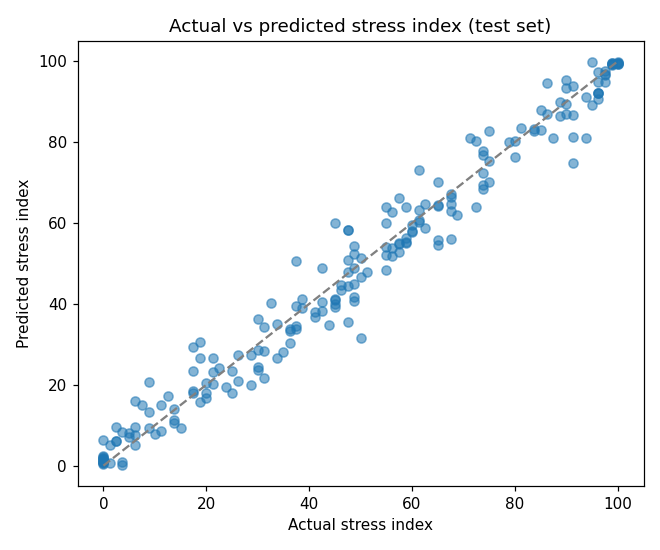

In [8]:
import matplotlib.pyplot as plt

predicted = model.predict(X_test)
plt.figure(figsize=(6, 5))
plt.scatter(y_test, predicted, alpha=0.55)
plt.plot([0, 100], [0, 100], linestyle='--', color='gray')
plt.xlabel('Actual stress index')
plt.ylabel('Predicted stress index')
plt.title('Actual vs predicted stress index (test set)')
plt.tight_layout()
plt.show()

## 7. Optional check: where the target comes from

In the full dataset, the stress index is exactly a formula of the 20 scale answers (B1 to E2), with the two "positive" statements
B4 (sleep) and B6 (physical activity) reversed. This is why the model reaches a high score: it learns that formula.
This cell needs `students_stress_dataset_age_balanced.csv`.

In [9]:
FULL = Path('students_stress_dataset_age_balanced.csv')
if not FULL.exists():
    FULL = Path('data') / FULL.name
if FULL.exists():
    full = pd.read_csv(FULL)
    scale = [c for c in full.columns if c[0] in 'BCDE' and c[1].isdigit() and pd.api.types.is_numeric_dtype(full[c])]
    reversed_columns = [c for c in scale if c.startswith(('B4_', 'B6_'))]
    total = sum((6 - full[c]) if c in reversed_columns else full[c] for c in scale)
    formula = (total - len(scale)) / (4 * len(scale)) * 100
    print(f'{len(scale)} scale questions, reversed: {reversed_columns}')
    print('Largest difference between the formula and the dataset index:',
          round(float((formula - full[TARGET]).abs().max()), 2))
else:
    print('Upload students_stress_dataset_age_balanced.csv to run this check.')

20 scale questions, reversed: ['B4_Sufficient_Sleep', 'B6_Physical_Activity']
Largest difference between the formula and the dataset index: 0.05


## 8. Save the model

The website loads this file. Train it again on every machine that runs the website, so it matches that machine's scikit-learn version.

In [10]:
MODEL_PATH = Path('student_stress_model.joblib')
joblib.dump(model, MODEL_PATH)
print(f'Saved {MODEL_PATH} (scikit-learn {sklearn.__version__})')

Saved student_stress_model.joblib (scikit-learn 1.8.0)
